<a href="https://colab.research.google.com/github/iampriyanka01/Module3-AI-agent-and-Multiagent-Systems/blob/main/Module_3_Session_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -q langgraph "langchain>=1.0" "langchain-google-genai>=4.0,<4.4" langchain-pinecone pinecone langchain-text-splitters langchain-huggingface sentence-transformers tavily-python requests python-dotenv

In [ ]:
import os
from getpass import getpass

def load_key(name, required=True):
    """Find a key in Colab Secrets, then in .env, then (if required) ask for it."""
    try:
        from google.colab import userdata          # only exists on Colab
        os.environ[name] = userdata.get(name)
    except Exception:
        pass
    if not os.getenv(name):
        from dotenv import load_dotenv
        load_dotenv(".env")
    if not os.getenv(name) and required:
        os.environ[name] = getpass(f"Paste your {name}: ")
    return os.getenv(name, "")

load_key("GOOGLE_API_KEY")
load_key("PINECONE_API_KEY")
if load_key("TAVILY_API_KEY", required=False):
    print("Tavily key found: web search will use Tavily.")
else:
    print("No Tavily key: web search will use free Wikipedia.")

Tavily key found: web search will use Tavily.


In [ ]:
from langchain_core.rate_limiters import InMemoryRateLimiter
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
from langchain_huggingface import HuggingFaceEmbeddings

limiter = InMemoryRateLimiter(requests_per_second=4 / 60, check_every_n_seconds=0.5, max_bucket_size=1)
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", rate_limiter=limiter)

gemini_embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001", output_dimensionality=768)
minilm_embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

print("Gemini vector size:", len(gemini_embeddings.embed_query("hello")))
print("MiniLM vector size:", len(minilm_embeddings.embed_query("hello")))

In [ ]:
from pinecone import Pinecone, ServerlessSpec

pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])
for name, dimension in [("session11-gemini", 768), ("session11-minilm", 384)]:
    if not pc.has_index(name):
        print(f"Creating index {name} ({dimension} dimensions)...")
        pc.create_index(name=name, dimension=dimension, metric="cosine",
                        spec=ServerlessSpec(cloud="aws", region="us-east-1"))

gemini_index = pc.Index("session11-gemini")
minilm_index = pc.Index("session11-minilm")
print("Indexes ready.")

Creating index session11-gemini (768 dimensions)...
Creating index session11-minilm (384 dimensions)...
Indexes ready.


In [ ]:
import time
from IPython.display import Image, display

def has_namespace(index, namespace):
    """True if this namespace already holds data (so we don't load it twice)."""
    return namespace in index.describe_index_stats().namespaces

def show_graph(app):
    """Draw a compiled LangGraph graph (or print it as text, if there's no internet)."""
    try:
        display(Image(app.get_graph().draw_mermaid_png()))
    except Exception:
        print(app.get_graph().draw_mermaid())

In [ ]:
%%writefile sample.txt
The Transformer is a novel neural network architecture introduced in the 'Attention Is All You Need' paper that completely eliminates recurrence and convolution, relying instead solely on attention mechanisms. The model uses stacked self-attention and point-wise fully connected layers in both encoder and decoder components. Key innovations include multi-head attention which allows the model to jointly attend to information from different representation subspaces, positional encoding to inject sequence order information, and scaled dot-product attention for efficient computation. The Transformer achieves superior performance on machine translation tasks while being more parallelizable and requiring significantly less time to train compared to recurrent or convolutional models."

Additional shorter paragraphs for more testing:

On Self-Attention:
"Self-attention, sometimes called intra-attention, is an attention mechanism that relates different positions of a single sequence to compute a representation of the sequence. It uses three matrices: Query, Key, and Value, and calculates attention weights through scaled dot-products. This allows each position to attend to all positions in the previous layer, enabling the model to capture long-range dependencies more effectively than recurrent networks."

On Multi-Head Attention:
"Multi-head attention consists of multiple attention heads running in parallel, each with their own learned linear projections. This allows the model to jointly attend to information from different representation subspaces at different positions. The outputs of all heads are concatenated and linearly transformed to produce the final values, giving the model greater capacity to focus on different aspects of the input sequence simultaneously

Writing sample.txt


In [ ]:
# Batch
# LSESRG
# Load -> Split -> Embed -> Store
# User Query -> # Retrieve -> Generate

In [ ]:
# NAIVE RAG

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(chunk_size=200, chunk_overlap=50)

def chunk_text(text):
    return splitter.split_text(text)

def get_embedding(text):
    return gemini_embeddings.embed_query(text)

def store_documents(chunks):
    vectors = gemini_embeddings.embed_documents(chunks)
    records = []
    for number in range(len(chunks)):
        records.append({"id": f"chunk-{number}", "values": vectors[number], "metadata": {"text": chunks[number]}})
    gemini_index.upsert(vectors=records, namespace="notes")
    print(f"Stored {len(records)} chunks")

In [ ]:
def retrieve_relevant_chunks(query, top_k=3):
    results = gemini_index.query(vector=get_embedding(query), top_k=top_k, include_metadata=True, namespace="notes")
    chunks = []
    for match in results.matches:
        chunks.append({"text": match.metadata["text"], "score": float(match.score)})
    return chunks

def generate_answer(query, context_chunks):
    context = "\n\n".join(context_chunks)
    return llm.invoke("Answer using ONLY this context. If it doesn't contain the answer, say "
                      "\"I cannot answer based on the provided information.\"\n\n"
                      f"Context:\n{context}\n\nQuestion: {query}\n\nAnswer:").text

def query(question, top_k=3):
    chunks = retrieve_relevant_chunks(question, top_k)
    texts = []
    for chunk in chunks:
        texts.append(chunk["text"])
    return generate_answer(question, texts)

In [ ]:
if not has_namespace(gemini_index, "notes"):
    with open("sample.txt", encoding="utf-8") as file:
        store_documents(chunk_text(file.read()))
    time.sleep(10)

print(query("What is multi-head attention?"))

Stored 15 chunks
Multi-head attention consists of multiple attention heads running in parallel, each with their own learned linear projections.


In [ ]:
# Modular

In [ ]:
# RAG using LangChain

In [ ]:
%%writefile students.txt
Aarav Sharma, grade 10, GPA 3.8, subjects: Math, Physics, Chemistry.
Diya Patel, grade 11, GPA 3.9, subjects: Biology, Chemistry, English.
Kabir Singh, grade 10, GPA 3.4, subjects: Math, Computer Science, English.
Meera Iyer, grade 12, GPA 4.0, subjects: Math, Economics, History.
Rohan Gupta, grade 11, GPA 3.2, subjects: Biology, Physics, Hindi.
Ananya Rao, grade 10, GPA 3.7, subjects: Biology, Math, Art.
Ishaan Verma, grade 12, GPA 3.5, subjects: Computer Science, Math, Physics.
Sara Khan, grade 11, GPA 3.6, subjects: English, History, Economics.

Writing students.txt


In [ ]:
from langchain_pinecone import PineconeVectorStore
from langchain_text_splitters import CharacterTextSplitter

students_store = PineconeVectorStore(index=gemini_index, embedding=gemini_embeddings, namespace="students")

if not has_namespace(gemini_index, "students"):
    with open("students.txt", encoding="utf-8") as file:
        records = CharacterTextSplitter(separator="\n", chunk_size=100, chunk_overlap=0).split_text(file.read())
    students_store.add_texts(records)          # LangChain embeds and stores them for us
    print(f"Stored {len(records)} student records")
    time.sleep(10)

Stored 8 student records


In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class RAGState(TypedDict):
    question: str
    context: str
    answer: str

def retrieve_documents(state: RAGState):
    documents = students_store.similarity_search(state["question"], k=3)
    texts = []
    for document in documents:
        texts.append(document.page_content)
    return {"context": "\n".join(texts)}

def generate(state: RAGState):
    return {"answer": llm.invoke(f"Answer from this student data only:\n{state['context']}\n\n"
                                 f"Question: {state['question']}").text}

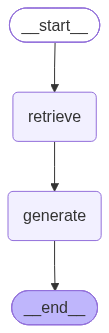


Q: Which students are in grade 10?
A: Based on the provided data, all the students are in grade 10:

* Kabir Singh
* Ananya Rao
* Aarav Sharma

Q: Who has the highest GPA?
A: Based on the student data provided, Meera Iyer has the highest GPA with a 4.0.


In [ ]:
graph = StateGraph(RAGState)
graph.add_node("retrieve", retrieve_documents)
graph.add_node("generate", generate)
graph.add_edge(START, "retrieve")
graph.add_edge("retrieve", "generate")
graph.add_edge("generate", END)
student_rag = graph.compile()
show_graph(student_rag)

for question in ["Which students are in grade 10?", "Who has the highest GPA?"]:
    print(f"\nQ: {question}\nA: {student_rag.invoke({'question': question})['answer']}")

In [ ]:
# Agentic RAG

In [ ]:
# Orders - User, Status
# Products - Name, Price, Description
# Support - Warranty, Returns, Shipping

In [ ]:
os.makedirs("knowledgebase", exist_ok=True)

In [ ]:
%%writefile knowledgebase/order.csv
order_id,user_name,product_name,status,date
5001,John Doe,Wireless Mouse,Delivered,2024-08-15
5002,Jane Smith,Gaming Keyboard,Shipped,2024-08-20
5003,John Doe,Noise Cancelling Headphones,Processing,2024-08-21
5004,Alice Brown,Laptop Stand,Delivered,2024-08-10
5005,Jane Smith,4K Monitor,Cancelled,2024-08-05
5006,Michael Lee,Bluetooth Speaker,Delivered,2024-07-28
5007,Chris Johnson,Smartwatch,Processing,2024-08-22
5008,Sophia Taylor,Coffee Maker,Shipped,2024-08-19
5011,Oliver Brown,Air Fryer,Processing,2024-08-18
5014,Isabella Garcia,Tablet,Processing,2024-08-23
5022,Benjamin Allen,Wireless Earbuds,Processing,2024-08-23
5029,Jackson Nelson,Laptop Stand,Processing,2024-08-22

Writing knowledgebase/order.csv


In [ ]:
%%writefile knowledgebase/product.csv
product_id,product_name,description,price
101,Wireless Mouse,Ergonomic wireless mouse with 2.4GHz USB receiver,19.99
102,Gaming Keyboard,Mechanical keyboard with RGB backlight,59.99
103,Noise Cancelling Headphones,Bluetooth over-ear headphones with noise cancellation,129.99
104,4K Monitor,27-inch 4K UHD display with HDMI and DisplayPort,299.99
105,Laptop Stand,Adjustable aluminum laptop stand for desks,39.99
106,USB-C Hub,"Multiport adapter with HDMI, USB 3.0, and SD card reader",49.99
107,Portable SSD,1TB USB-C portable solid state drive,149.99
108,Webcam,1080p HD webcam with built-in microphone,79.99
110,Bluetooth Speaker,Portable waterproof Bluetooth speaker,89.99
116,Smartwatch,Fitness tracking smartwatch with heart rate monitor,249.99
118,Wireless Earbuds,True wireless earbuds with charging case,99.99
127,Air Fryer,5L digital air fryer with temperature control,149.99

Writing knowledgebase/product.csv


In [ ]:
%%writefile knowledgebase/support_catalogue.csv
faq_id,question,answer
1,How do I return a product?,You can return a product within 30 days using the returns portal in your account.
2,What is the warranty on electronics?,Most electronics have a 1-year manufacturer warranty. Please check the product page.
3,How can I track my order?,You can track your order from the Orders section in your account dashboard.
5,What payment methods are accepted?,"We accept credit cards, debit cards, PayPal, and gift vouchers."
6,How do I cancel an order?,You can cancel an order within 24 hours before it ships by visiting your Orders page.
7,What if my product is damaged?,"If your product arrives damaged, please contact support within 48 hours for a replacement."
9,Can I change my delivery address?,You can change your delivery address before the order ships from your account settings.
11,What are your customer support hours?,Our support team is available 24/7 via chat and email.
12,Do you offer student discounts?,"Yes, students can register with a valid ID for a 10% discount."
22,Do you provide express delivery?,"Yes, express delivery is available for an extra charge at checkout."
24,Do you provide extended warranty?,"Yes, extended warranty plans are available for select electronics."
25,Can I return used products?,"No, only unused products in original condition are eligible for return."

Writing knowledgebase/support_catalogue.csv


In [ ]:
import csv

DOMAINS = {"orders": "knowledgebase/order.csv", "products": "knowledgebase/product.csv",
           "support": "knowledgebase/support_catalogue.csv"}

def shop_store(domain):
    return PineconeVectorStore(index=minilm_index, embedding=minilm_embeddings, namespace=domain)

for domain in DOMAINS:
    if has_namespace(minilm_index, domain):
        continue
    texts = []
    with open(DOMAINS[domain], encoding="utf-8") as file:
        for row in csv.DictReader(file):
            parts = []
            for column in row:
                parts.append(f"{column}: {row[column]}")
            texts.append(", ".join(parts))
    shop_store(domain).add_texts(texts)
    print(f"{domain}: stored {len(texts)} rows")
time.sleep(10)

orders: stored 12 rows
products: stored 12 rows
support: stored 12 rows


In [ ]:
route_schema = {
    "title": "route", "type": "object", "description": "Which domains hold the answer",
    "properties": {"domains": {"type": "array", "items": {"type": "string", "enum": ["orders", "products", "support"]}}},
    "required": ["domains"],
}

sufficiency_schema = {
    "title": "sufficiency", "type": "object", "description": "Whether the context is enough to answer",
    "properties": {"sufficient": {"type": "boolean"}, "missing": {"type": "string"}},
    "required": ["sufficient", "missing"],
}

In [ ]:
class AgentState(TypedDict):
    question: str
    domains: list
    context: str
    sufficient: bool
    expanded: bool
    answer: str

In [ ]:
def route(state: AgentState):
    choice = llm.with_structured_output(route_schema).invoke(
        "Which hold the answer? orders (status, who ordered what), products (descriptions, prices), "
        "support (returns, warranty, shipping). Pick only what's needed.\n\nQuestion: " + state["question"])
    domains = choice["domains"]
    if len(domains) == 0:
        domains = list(DOMAINS.keys())
    print(f"   [route] -> {domains}")
    return {"domains": domains, "expanded": False}

def retrieve(state: AgentState):
    lines = []
    for domain in state["domains"]:
        for document in shop_store(domain).similarity_search(state["question"], k=4):
            lines.append(f"[{domain}] {document.page_content}")
    print(f"   [retrieve] {len(lines)} records from {state['domains']}")
    return {"context": "\n".join(lines)}

In [ ]:
def check_sufficiency(state: AgentState):
    verdict = llm.with_structured_output(sufficiency_schema).invoke(
        f"Question: {state['question']}\n\nContext:\n{state['context']}\n\nIs this enough to answer fully?")
    print(f"   [check] sufficient: {verdict['sufficient']} {verdict['missing']}")
    return {"sufficient": verdict["sufficient"]}

def expand(state: AgentState):
    print("   [expand] not enough: searching every domain")
    return {"domains": list(DOMAINS.keys()), "expanded": True}

def answer(state: AgentState):
    return {"answer": llm.invoke("You are a support agent for an electronics shop. Answer using ONLY the context.\n\n"
                                 f"Context:\n{state['context']}\n\nQuestion: {state['question']}").text}

def after_check(state: AgentState) -> str:
    if state["sufficient"] or state["expanded"]:     # enough, or we already widened the search once
        return "answer"
    return "expand"

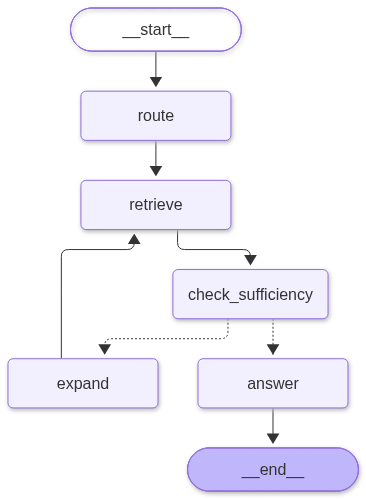

In [ ]:
graph = StateGraph(AgentState)
graph.add_node("route", route)
graph.add_node("retrieve", retrieve)
graph.add_node("check_sufficiency", check_sufficiency)
graph.add_node("expand", expand)
graph.add_node("answer", answer)
graph.add_edge(START, "route")
graph.add_edge("route", "retrieve")
graph.add_edge("retrieve", "check_sufficiency")
graph.add_conditional_edges("check_sufficiency", after_check, ["answer", "expand"])
graph.add_edge("expand", "retrieve")
graph.add_edge("answer", END)
single_agent = graph.compile()
show_graph(single_agent)

In [ ]:
for question in ["What is the status of order 5003?", "How much did Jane Smith's keyboard cost?"]:
    print(f"\nQ: {question}")
    print("A:", single_agent.invoke({"question": question})["answer"])


Q: What is the status of order 5003?
   [route] -> ['orders']
   [retrieve] 4 records from ['orders']
   [check] sufficient: False The context does not contain information about order 5003.
   [expand] not enough: searching every domain
   [retrieve] 12 records from ['orders', 'products', 'support']
   [check] sufficient: False The status of order 5003 is not present in the context.
A: I'm sorry, but the provided context does not contain any information about order 5003.

Q: How much did Jane Smith's keyboard cost?
   [route] -> ['orders', 'products']
   [retrieve] 8 records from ['orders', 'products']
   [check] sufficient: True 
A: Jane Smith's keyboard (Gaming Keyboard) cost $59.99.


In [ ]:
import requests

def web_search(query):
    """Tavily if there's a key, otherwise Wikipedia. Returns a list of {"title", "content"}."""
    try:
        if os.getenv("TAVILY_API_KEY"):
            from tavily import TavilyClient
            response = TavilyClient(api_key=os.environ["TAVILY_API_KEY"]).search(query=query, max_results=3)
            results = []
            for item in response.get("results", []):
                results.append({"title": item.get("title", ""), "content": item.get("content", "")})
            return results
        headers = {"User-Agent": "GenAI-course/1.0 (educational use)"}
        found = requests.get("https://en.wikipedia.org/w/api.php", headers=headers, timeout=20,
                             params={"action": "query", "list": "search", "srsearch": query, "format": "json"}).json()
        title = found["query"]["search"][0]["title"]
        page = requests.get("https://en.wikipedia.org/w/api.php", headers=headers, timeout=20,
                            params={"action": "query", "prop": "extracts", "exintro": 1, "explaintext": 1,
                                    "titles": title, "format": "json"}).json()
        for page_id in page["query"]["pages"]:
            return [{"title": title, "content": page["query"]["pages"][page_id].get("extract", "")[:2000]}]
    except Exception as error:
        print(f"   [web search] unavailable: {type(error).__name__}")
    return []

In [ ]:
crag_schema = {
    "title": "sufficiency", "type": "object", "description": "Can the retrieved context fully answer the query?",
    "properties": {"label": {"type": "string", "enum": ["sufficient", "partial", "insufficient"]},
                   "reason": {"type": "string"}},
    "required": ["label", "reason"],
}

class CRAGState(TypedDict):
    query: str
    retrieved_chunks: list
    draft_answer: str
    sufficiency: str
    web_search_results: list
    final_answer: str

In [ ]:
def retrieve_and_draft(state: CRAGState):
    """a. Retrieval and draft answer, with Part 1's naive RAG."""
    chunks = retrieve_relevant_chunks(state["query"])
    texts = []
    for chunk in chunks:
        texts.append(chunk["text"])
    print(f"   [retrieve] {len(chunks)} chunks")
    return {"retrieved_chunks": chunks, "draft_answer": generate_answer(state["query"], texts)}

def assess_context_sufficiency(state: CRAGState):
    """b. Is the context enough?"""
    context = ""
    for chunk in state["retrieved_chunks"]:
        context = context + chunk["text"] + "\n"
    verdict = llm.with_structured_output(crag_schema).invoke(
        f"Can this context fully answer the query?\n\nQuery: {state['query']}\n\nContext:\n{context}")
    print(f"   [assess] {verdict['label']}: {verdict['reason']}")
    return {"sufficiency": verdict["label"]}

In [ ]:
def perform_web_search(state: CRAGState):
    """c. Correction: bring in outside knowledge."""
    results = web_search(state["query"])
    print(f"   [web search] {len(results)} results")
    return {"web_search_results": results}

def generate_final_answer(state: CRAGState):
    """d. The final answer. If no web search was needed, the draft is already good."""
    if len(state.get("web_search_results", [])) == 0:
        return {"final_answer": state["draft_answer"]}
    contexts = []
    for chunk in state["retrieved_chunks"]:
        contexts.append(chunk["text"])
    for result in state["web_search_results"]:
        contexts.append(result["content"])
    return {"final_answer": llm.invoke("Use all the context to write a final, accurate answer.\n\nContext:\n" +
                                       "\n\n".join(contexts) + f"\n\nQuestion: {state['query']}").text}

def decide_next_step(state: CRAGState) -> str:
    if state["sufficiency"] == "sufficient":
        return "generate_final_answer"
    return "web_search"

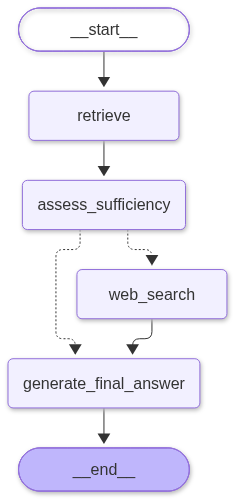

In [ ]:
def build_crag(state_type, checkpointer=None):
    graph = StateGraph(state_type)
    graph.add_node("retrieve", retrieve_and_draft)
    graph.add_node("assess_sufficiency", assess_context_sufficiency)
    graph.add_node("web_search", perform_web_search)
    graph.add_node("generate_final_answer", generate_final_answer)
    graph.add_edge(START, "retrieve")
    graph.add_edge("retrieve", "assess_sufficiency")
    graph.add_conditional_edges("assess_sufficiency", decide_next_step, ["generate_final_answer", "web_search"])
    graph.add_edge("web_search", "generate_final_answer")
    graph.add_edge("generate_final_answer", END)
    return graph.compile(checkpointer=checkpointer)

crag = build_crag(CRAGState)
show_graph(crag)

In [ ]:
for question in ["What is multi-head attention?", "What were the main developments in quantum computing in 2026?"]:
    print(f"\nQ: {question}")
    result = crag.invoke({"query": question, "web_search_results": []})
    print(f"   context: {result['sufficiency']} | web search used: {len(result['web_search_results']) > 0}")
    print("A:", result["final_answer"])


Q: What is multi-head attention?
   [retrieve] 3 chunks
   [assess] partial: The context explains what multi-head attention is and its basic mechanism, but the text is cut off at the end and does not provide a complete and comprehensive explanation.
   [web search] 3 results
   context: partial | web search used: True
A: Based on the provided context, **multi-head attention (MHA)** is an extension of the self-attention mechanism in transformer architectures where several attention modules (or "heads") run in parallel. 

Instead of performing a single attention pooling using one set of queries, keys, and values ($Q$, $K$, $V$), multi-head attention operates through the following steps:

1. **Linear Projections:** The input embeddings are projected into multiple smaller-dimensional subspaces in parallel using different learned weight matrices ($W_q$, $W_k$, and $W_v$). 
2. **Independent Attention Computation:** Each head independently computes its own self-attention (using mechanisms li

In [ ]:
import operator
from typing import Annotated
from langgraph.checkpoint.memory import InMemorySaver

class MemoryState(TypedDict):
    question: str                              # what the user typed
    query: str                                 # the standalone version used for searching
    history: Annotated[list, operator.add]     # each turn adds to this list
    retrieved_chunks: list
    draft_answer: str
    sufficiency: str
    web_search_results: list
    final_answer: str

In [ ]:
def rewrite_question(state: MemoryState):
    if len(state.get("history", [])) == 0:
        return {"query": state["question"]}
    standalone = llm.invoke("Rewrite the follow-up as a standalone question, using the conversation. "
                            "Reply with the question only.\n\nConversation:\n" + "\n".join(state["history"][-6:]) +
                            f"\n\nFollow-up: {state['question']}").text.strip()
    print(f"   [memory] '{state['question']}' -> '{standalone}'")
    return {"query": standalone}

def remember(state: MemoryState):
    return {"history": [f"User: {state['question']}", f"Assistant: {state['final_answer']}"]}

In [ ]:
memory = InMemorySaver()

graph = StateGraph(MemoryState)
graph.add_node("rewrite_question", rewrite_question)
graph.add_node("retrieve", retrieve_and_draft)          # the same CRAG nodes as Part 5
graph.add_node("assess_sufficiency", assess_context_sufficiency)
graph.add_node("web_search", perform_web_search)
graph.add_node("generate_final_answer", generate_final_answer)
graph.add_node("remember", remember)
graph.add_edge(START, "rewrite_question")
graph.add_edge("rewrite_question", "retrieve")
graph.add_edge("retrieve", "assess_sufficiency")
graph.add_conditional_edges("assess_sufficiency", decide_next_step, ["generate_final_answer", "web_search"])
graph.add_edge("web_search", "generate_final_answer")
graph.add_edge("generate_final_answer", "remember")
graph.add_edge("remember", END)
crag_with_memory = graph.compile(checkpointer=memory)

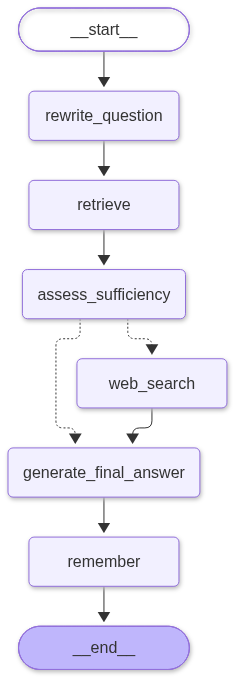

In [ ]:
show_graph(crag_with_memory)

In [ ]:
def chat(question, session_id="default"):
    config = {"configurable": {"thread_id": session_id}}
    fresh = {"question": question, "retrieved_chunks": [], "web_search_results": [], "draft_answer": "", "final_answer": ""}
    return crag_with_memory.invoke(fresh, config)["final_answer"]

def get_session_history(session_id="default"):
    return crag_with_memory.get_state({"configurable": {"thread_id": session_id}}).values.get("history", [])

def clear_session(session_id="default"):
    memory.delete_thread(session_id)

In [ ]:
print("Turn 1:", chat("What is self-attention?", "user_123"))
print("\nTurn 2:", chat("How is it different from multi-head attention?", "user_123"))

   [retrieve] 3 chunks
   [assess] partial: The context explains what self-attention is and mentions its components (Query, Key, and Value matrices, scaled dot-products), but the text is cut off and incomplete, lacking a full explanation of how it operates end-to-end.
   [web search] 3 results
Turn 1: Based on the provided context, **self-attention** (sometimes called intra-attention) is an attention mechanism used in machine learning—particularly in natural language processing (NLP) and computer vision—that allows a single sequence to attend to itself, relating different positions of the sequence to compute a context-aware representation. 

Key aspects of self-attention include:
* **How it works:** It transforms the input sequence into three vectors—**Query (Q)**, **Key (K)**, and **Value (V)**—through linear transformations and learned weight matrices ($W_Q, W_K, W_V$). It then calculates attention weights through scaled dot-products (measuring the similarity between the query and ke

In [ ]:
domains_schema = {
    "title": "domains", "type": "object", "description": "The domains the question needs",
    "properties": {"domains": {"type": "array", "items": {"type": "string", "enum": ["orders", "products", "support"]}}},
    "required": ["domains"],
}
evaluation_schema = {
    "title": "evaluation", "type": "object", "description": "The critic's verdict on the findings",
    "properties": {"evaluation": {"type": "string", "enum": ["sufficient", "insufficient"]}, "reason": {"type": "string"}},
    "required": ["evaluation", "reason"],
}

class TeamState(TypedDict):
    question: str
    domains: list
    context: str
    findings: str
    evaluation: str
    critique: str
    rounds: int
    answer: str

In [ ]:
def orchestrator(state: TeamState):
    choice = llm.with_structured_output(domains_schema).invoke(
        "You are the ORCHESTRATOR agent. Choose the domains this question needs: orders, products, support.\n\n"
        "Question: " + state["question"])
    domains = choice["domains"]
    if len(domains) == 0:
        domains = list(DOMAINS.keys())
    print(f"   [orchestrator] -> {domains}")
    return {"domains": domains, "rounds": 0}

def researcher(state: TeamState):
    domains = state["domains"]
    if state["rounds"] > 0:
        domains = list(DOMAINS.keys())          # sent back by the critic: search everywhere
    lines = []
    for domain in domains:
        for document in shop_store(domain).similarity_search(state["question"], k=4):
            lines.append(f"[{domain}] {document.page_content}")
    print(f"   [researcher] round {state['rounds'] + 1}: {len(lines)} records from {domains}")
    return {"context": "\n".join(lines), "rounds": state["rounds"] + 1}

In [ ]:
def analyst(state: TeamState):
    return {"findings": llm.invoke("You are the ANALYST agent. Extract the facts that answer the question, as a short "
                                   f"bullet list.\n\nQuestion: {state['question']}\n\nContext:\n{state['context']}").text}

def critic(state: TeamState):
    verdict = llm.with_structured_output(evaluation_schema).invoke(
        "You are the CRITIC agent. Evaluate the analyst's findings for accuracy and completeness.\n\n"
        f"Question: {state['question']}\n\nFindings:\n{state['findings']}")
    print(f"   [critic] {verdict['evaluation']}: {verdict['reason']}")
    return {"evaluation": verdict["evaluation"], "critique": verdict["reason"]}

def synthesizer(state: TeamState):
    return {"answer": llm.invoke("You are the SYNTHESIZER agent. Write a clear answer from the findings, considering "
                                 f"the critique.\n\nQuestion: {state['question']}\n\nFindings:\n{state['findings']}\n\n"
                                 f"Critique: {state['critique']}").text}

def after_critic(state: TeamState) -> str:
    if state["evaluation"] == "insufficient" and state["rounds"] < 2:
        return "researcher"
    return "synthesizer"

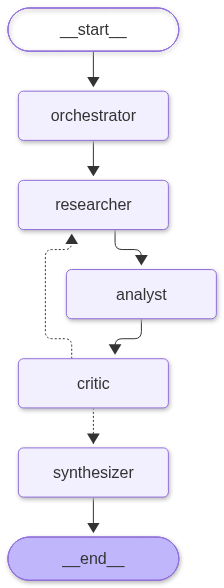

In [ ]:
graph = StateGraph(TeamState)
for name, agent in [("orchestrator", orchestrator), ("researcher", researcher), ("analyst", analyst),
                    ("critic", critic), ("synthesizer", synthesizer)]:
    graph.add_node(name, agent)
graph.add_edge(START, "orchestrator")
graph.add_edge("orchestrator", "researcher")
graph.add_edge("researcher", "analyst")
graph.add_edge("analyst", "critic")
graph.add_conditional_edges("critic", after_critic, ["researcher", "synthesizer"])
graph.add_edge("synthesizer", END)
team = graph.compile()
show_graph(team)

In [ ]:
result = team.invoke({"question": "Jane Smith wants to cancel her keyboard order. Can she, and how much was it?"})
print("\n--- Findings ---\n" + result["findings"])
print("\n--- Critique ---\n" + result["critique"])
print("\n--- Answer ---\n" + result["answer"])

   [orchestrator] -> ['orders', 'products']
   [researcher] round 1: 8 records from ['orders', 'products']
   [critic] sufficient: The findings accurately answer both parts of the user's question by stating that the order cannot be cancelled due to its 'Shipped' status and correctly identifying the price of the Gaming Keyboard as $59.99.

--- Findings ---
- Jane Smith cannot cancel her keyboard order because the status is "Shipped".
- The price of the Gaming Keyboard is $59.99.

--- Critique ---
The findings accurately answer both parts of the user's question by stating that the order cannot be cancelled due to its 'Shipped' status and correctly identifying the price of the Gaming Keyboard as $59.99.

--- Answer ---
Jane Smith cannot cancel her keyboard order because its status is already "Shipped." The price of the gaming keyboard is $59.99.
